In [1]:
!pip install -q hazm bm25s sentence-transformers pyarrow openai

In [2]:
import os
PKG = "/kaggle/working/package"
os.makedirs(PKG, exist_ok=True)

In [3]:
%%writefile /kaggle/working/package/search_engine.py
import json
import os
import re
import numpy as np
import pandas as pd
import bm25s
from hazm import Normalizer

_norm = Normalizer()


def normalize(s):
    return _norm.normalize(s)


def tokenize(s):
    return re.findall(r"\w+", s)


def rrf(lists, k=60):
    score = {}
    for lst in lists:
        for rank, i in enumerate(lst):
            score[i] = score.get(i, 0.0) + 1.0 / (k + rank + 1)
    return [i for i, _ in sorted(score.items(), key=lambda x: -x[1])]


CHEAP_WORDS = {"ارزان", "ارزون", "ارزانی", "اقتصادی"}
EXPENSIVE_WORDS = {"گرون", "گران"}
NEGATION_WORDS = {"نباشه", "نباشد", "نباشن", "نباشند"}
SATISFIED_PREFIX = ("راضی", "رضایت")
SATISFIED_WORDS = {"خریدارها", "خریداران", "خریدار", "مشتری", "مشتریا", "مشتریان", "کاربرا", "کاربران"}
FILLER = {"که", "هم", "ازش", "ازشون", "باشن", "باشند", "باشه", "باشد", "میخوام", "میخواهم",
          "می", "خوام", "خواهم", "خیلی", "لطفا", "لطفاً", "یه", "یک", "و", "را", "رو",
          "برام", "بهم", "پیدا", "کن", "بده", "معرفی", "قیمت"}


def parse_query(q):
    toks = tokenize(normalize(q))
    cheap = any(t in CHEAP_WORDS for t in toks) or (
        any(t in EXPENSIVE_WORDS for t in toks) and any(t in NEGATION_WORDS for t in toks))
    satisfied = any(t.startswith(SATISFIED_PREFIX) or t in SATISFIED_WORDS for t in toks)
    drop = CHEAP_WORDS | EXPENSIVE_WORDS | NEGATION_WORDS | SATISFIED_WORDS | FILLER
    kept = [t for t in toks if t not in drop and not t.startswith(SATISFIED_PREFIX)]
    return (" ".join(kept) if kept else q), cheap, satisfied


class SearchEngine:
    COLS = ["id", "title_fa", "Brand", "price_toman", "bayes_rate", "mean_rate",
            "n_comments", "pct_rec", "Rate_cnt", "Category1", "Category2"]

    def __init__(self, pkg_dir=None, model_path=None, device="cpu"):
        pkg_dir = pkg_dir or os.path.dirname(os.path.abspath(__file__))
        with open(os.path.join(pkg_dir, "meta.json"), encoding="utf-8") as f:
            self.meta = json.load(f)
        self.df = pd.read_parquet(os.path.join(pkg_dir, "catalog.parquet"))
        q = np.load(os.path.join(pkg_dir, "emb_int8.npy"))
        self.E = q.astype(np.float32) * np.float32(self.meta["scale"])
        assert len(self.df) == len(self.E), "catalog and embeddings are out of sync"
        self.ids_arr = self.df["id"].to_numpy()
        self.title_norm = self.df["text"].str.split(" | ", n=1, regex=False).str[0]

        cache = os.path.join(pkg_dir, ".bm25_cache")
        self.bm25 = None
        if os.path.isdir(cache):
            try:
                self.bm25 = bm25s.BM25.load(cache, load_corpus=False)
            except Exception:
                self.bm25 = None
        if self.bm25 is None:
            self.bm25 = bm25s.BM25()
            self.bm25.index([tokenize(t) for t in self.df["text"]], show_progress=False)
            try:
                self.bm25.save(cache)
            except Exception:
                pass

        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_path or self.meta["model"], device=device)
        self.model.max_seq_length = self.meta["max_len"]

    def _bm25(self, q, n):
        toks = tokenize(normalize(q))
        if not toks:
            return np.array([], dtype=int)
        idx, _ = self.bm25.retrieve([toks], k=n, show_progress=False)
        return idx[0]

    def _emb(self, q, n):
        v = self.model.encode([self.meta["query_prefix"] + normalize(q)],
                              normalize_embeddings=True)[0].astype(np.float32)
        s = self.E @ v
        top = np.argpartition(-s, n)[:n]
        return top[np.argsort(-s[top])]

    def positions(self, q, mode="hybrid", n=300):
        if mode == "bm25":
            return self._bm25(q, n)
        if mode == "emb":
            return self._emb(q, n)
        if mode == "hybrid":
            return np.array(rrf([list(self._bm25(q, n)), list(self._emb(q, n))]), dtype=int)
        raise ValueError("mode must be 'bm25', 'emb' or 'hybrid'")

    def ids(self, q, mode="hybrid", k=10, n=300):
        return self.ids_arr[self.positions(q, mode, n)[:k]].tolist()

    def search(self, q, k=10, mode="hybrid", max_price_toman=None, min_price_toman=None,
               min_rate=None, n=300, parse=True, pool=100, same_category=False,
               head_boost=True):
        cheap = satisfied = False
        cq = q
        if parse:
            cq, cheap, satisfied = parse_query(q)
        has_filter = max_price_toman is not None or min_price_toman is not None or min_rate is not None
        depth = max(n, 2000) if has_filter else n
        pos = self.positions(cq, mode, depth)
        r = self.df.iloc[pos]
        tn = self.title_norm.iloc[pos]

        if same_category and len(r):
            cats = r.head(30)["Category2"].value_counts().head(2).index
            keep = r["Category2"].isin(cats).to_numpy()
            r, tn = r[keep], tn[keep]
        keep = np.ones(len(r), dtype=bool)
        if max_price_toman is not None:
            keep &= (r["Price"] <= max_price_toman * 10).to_numpy()
        if min_price_toman is not None:
            keep &= (r["Price"] >= min_price_toman * 10).to_numpy()
        if min_rate is not None:
            keep &= (r["bayes_rate"] >= min_rate).to_numpy()
        r, tn = r[keep], tn[keep]

        if head_boost and len(r):
            head = tokenize(normalize(cq))
            if head:
                pat = r"(?<!\w)" + re.escape(head[0]) + r"(?!\w)"
                has = tn.str.contains(pat, regex=True).to_numpy()
                r = pd.concat([r[has], r[~has]])

        r = r.head(pool)
        if cheap and max_price_toman is None and len(r):
            r = r[r["Price"] <= r["Price"].median()]
        if satisfied and min_rate is None and len(r) > 1:
            solid = r[r["n_comments"] >= 20]
            if len(solid) >= k:
                r = solid
            sim = np.linspace(1.0, 0.0, len(r))
            b = r["bayes_rate"].to_numpy(dtype=float)
            qual_b = (b - b.min()) / (b.max() - b.min() + 1e-9)
            qual = 0.7 * qual_b + 0.3 * r["pct_rec"].to_numpy(dtype=float)
            r = r.iloc[np.argsort(-(0.6 * sim + 0.4 * qual), kind="stable")]

        r = r.head(k).copy()
        r["price_toman"] = (r["Price"] / 10).astype(int)
        return r[self.COLS].reset_index(drop=True)

Writing /kaggle/working/package/search_engine.py


In [4]:
import sys, gc, json, time, shutil, glob
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, PKG)
from search_engine import normalize

D = "/kaggle/input/datasets/helia05/digikala-parquet"
MODEL, DP, QP, MAX_LEN = "intfloat/multilingual-e5-small", "passage: ", "query: ", 96
MIN_COMMENTS, MAX_ITEMS = 10, 100_000

products = pd.read_parquet(f"{D}/products_raw.parquet")
comments = pd.read_parquet(f"{D}/comments_raw.parquet",
                           columns=["id", "product_id", "rate", "recommendation_status"])
comments["is_rec"] = comments["recommendation_status"] == "recommended"
agg = (comments.groupby("product_id")
       .agg(n_comments=("id", "size"), mean_rate=("rate", "mean"), pct_rec=("is_rec", "mean"))
       .reset_index())
del comments
gc.collect()

n0 = len(products)
products = products.sort_values("Price").drop_duplicates("id", keep="first").reset_index(drop=True)
print(f"{n0:,} -> {len(products):,}")

d = products.merge(agg, left_on="id", right_on="product_id", how="inner")
d = d[d["title_fa"].notna() & (d["Price"] > 0) & (d["n_comments"] >= MIN_COMMENTS)]
d = d.sort_values("n_comments", ascending=False, kind="stable").head(MAX_ITEMS).reset_index(drop=True)

C, m = d["mean_rate"].mean(), 20
d["bayes_rate"] = (d["n_comments"] * d["mean_rate"].fillna(C) + m * C) / (d["n_comments"] + m)

docs = [" | ".join(str(x) for x in row if pd.notna(x))
        for row in zip(d["title_fa"], d["Category1"], d["Category2"], d["Brand"])]
t = time.time()
d["text"] = [normalize(x) for x in docs]
print(f"{len(d):,} products | {time.time() - t:.0f}s")

KEEP = ["id", "title_fa", "Brand", "Category1", "Category2", "Price", "Rate_cnt",
        "n_comments", "mean_rate", "pct_rec", "bayes_rate", "text"]
catalog = d[KEEP].copy()
for c in ["mean_rate", "pct_rec", "bayes_rate"]:
    catalog[c] = catalog[c].astype("float32")
catalog["n_comments"] = catalog["n_comments"].astype("int32")
catalog["Rate_cnt"] = pd.to_numeric(catalog["Rate_cnt"], errors="coerce").fillna(0).astype("int32")
for c in ["Brand", "Category1", "Category2"]:
    catalog[c] = catalog[c].astype("string")

1,283,496 -> 948,352
98,035 products | 20s


In [5]:
from sentence_transformers import SentenceTransformer

enc = SentenceTransformer(MODEL, device="cuda")
enc.half()
enc.max_seq_length = MAX_LEN
t = time.time()
E = enc.encode([DP + x for x in catalog["text"]], batch_size=256,
               normalize_embeddings=True, show_progress_bar=True).astype("float32")
print(f"{time.time() - t:.0f}s | {E.shape}")

scale = float(np.abs(E).max() / 127)
E8 = np.clip(np.round(E / scale), -127, 127).astype(np.int8)
Edq = E8.astype(np.float32) * np.float32(scale)

rng = np.random.default_rng(0)
qi = rng.choice(len(E), 500, replace=False)
top = lambda S: np.argpartition(-S, 10, axis=1)[:, :10]
a, b = top(E[qi] @ E.T), top(E[qi] @ Edq.T)
recall = float(np.mean([len(set(x) & set(y)) / 10 for x, y in zip(a, b)]))
print(f"recall@10 int8 vs float32: {recall:.3f}")
del a, b
gc.collect()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/383 [00:00<?, ?it/s]

21s | (98035, 384)
recall@10 int8 vs float32: 0.968


45

In [6]:
catalog.to_parquet(f"{PKG}/catalog.parquet", index=False, compression="zstd")
np.save(f"{PKG}/emb_int8.npy", E8)
json.dump({"model": MODEL, "doc_prefix": DP, "query_prefix": QP, "max_len": MAX_LEN,
           "scale": scale, "dim": int(E.shape[1]), "n_docs": int(len(catalog)),
           "min_comments": MIN_COMMENTS, "recall10_int8_vs_fp32": round(recall, 4)},
          open(f"{PKG}/meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

open(f"{PKG}/requirements.txt", "w").write(
    "hazm\nbm25s\nsentence-transformers\npandas\npyarrow\nnumpy\ntorch\nopenai\n")

open(f"{PKG}/README.md", "w", encoding="utf-8").write("""# Digikala hybrid search + review QA

pip install -r requirements.txt

جست‌وجوی محصول:

    import sys
    sys.path.insert(0, "path/to/package")
    from search_engine import SearchEngine
    eng = SearchEngine()
    eng.search("کیف روزمره ارزان که خریدارها ازش راضی باشن", k=10)

پرسش و پاسخ از نظرها (فایل comments.parquet جداست):

    from reviews import ReviewSearch, make_client
    rs = ReviewSearch("path/to/comments.parquet", eng)
    rs.ask("ایرادهای پرتکرار این محصول چیست؟", product_id=123456)
    rs.ask("مردم از کیف دوشی گالری چی چاپ راضی بودند؟")
    rs.ask("آیا ارزش خرید دارد؟", product_id=123456, client=make_client())

- ستون id همان product_id در فایل نظرهاست.
- قیمت ورودی و خروجی به تومان است.
- بدون client خروجی ساخت‌یافته (آمار، موضوع‌های پرتکرار، شواهد با comment_id) برمی‌گردد.
- با client جواب متنی مبتنی بر شواهد با استناد [comment_id] تولید می‌شود. کلید باید در متغیر محیطی QBC13_API_KEY باشد.
- اولین اجرا مدل e5-small را دانلود می‌کند و ایندکس BM25 را حدود ۱۵ ثانیه می‌سازد.
""")

for f in sorted(os.listdir(PKG)):
    print(f"{f:22s} {os.path.getsize(os.path.join(PKG, f)) / 1e6:7.1f} MB")

README.md                  0.0 MB
__pycache__                0.0 MB
catalog.parquet            7.6 MB
emb_int8.npy              37.6 MB
meta.json                  0.0 MB
requirements.txt           0.0 MB
search_engine.py           0.0 MB


In [7]:
%%writefile /kaggle/working/package/reviews.py
import os
import re
import time
import numpy as np
import pandas as pd
from search_engine import normalize, tokenize

SPLIT = re.compile(r"[\n\r|؛;]+|[\[\]'\"]+")
CONS = ("ایراد", "عیب", "معایب", "مشکل", "ضعف", "شکایت", "ناراضی")
PROS = ("راضی", "مزایا", "مزیت", "قوت", "مثبت", "خوبی")
WORTH = ("ارزش", "میارزه", "می ارزه", "می‌ارزه", "بخرم", "توصیه", "پیشنهاد")
QUALITY = ("کیفیت",)
QWORDS = {"مردم", "بیشتر", "چه", "چیزی", "چیست", "این", "محصول", "پرتکرار", "خریداران", "خریدار",
          "درباره", "گفته", "اند", "آیا", "با", "توجه", "به", "تجربه", "کاربران", "ارزش", "خرید",
          "دارد", "بودند", "از", "در", "نظر", "نظرات", "کیفیت", "هست", "است", "مورد", "ی", "های",
          "ها", "چطور", "چطوره", "چیه", "رو", "را", "و", "که", "هم"}
QPREFIX = ("ایراد", "راضی", "مزایا", "معایب", "مشکل", "عیب", "رضایت", "شکایت")

SYSTEM = (
    "تو دستیار تحلیل نظرات کاربران یک فروشگاه اینترنتی هستی. فقط از اطلاعات و شواهدی که در پیام می‌آید استفاده کن "
    "و هیچ اطلاعاتی از خودت اضافه نکن. هر ادعا درباره‌ی نظر کاربران را با شناسه‌ی نظر به شکل [123456] مستند کن. "
    "اگر شواهد برای پاسخ کافی نیست، صریحاً بگو. پاسخ را به فارسی و در سه بخش بنویس: "
    "۱) اطلاعات مستقیم داده، ۲) شواهد از نظرها (با شناسه)، ۳) نتیجه‌گیری (به‌عنوان استنتاج مشخص شود). "
    "حداکثر ۱۵۰ کلمه."
)


def detect_intent(q):
    qn = normalize(q)
    for name, words in (("worth", WORTH), ("cons", CONS), ("pros", PROS), ("quality", QUALITY)):
        if any(w in qn for w in words):
            return name
    return "general"


def product_query(q):
    toks = [t for t in tokenize(normalize(q))
            if t not in QWORDS and not t.startswith(QPREFIX)]
    return " ".join(toks)


def split_points(text):
    if not isinstance(text, str):
        return []
    parts = [p.strip(" ,،.-•*") for p in SPLIT.split(text)]
    return [p for p in parts if len(p) >= 3]


def make_client(base_url="https://193.93.169.12/v1", env="QBC13_API_KEY", verify_ssl=True):
    from openai import OpenAI
    key = os.environ.get(env)
    if not key:
        raise RuntimeError(f"{env} is not set")
    if verify_ssl:
        return OpenAI(base_url=base_url, api_key=key)
    import httpx
    return OpenAI(base_url=base_url, api_key=key, http_client=httpx.Client(verify=False))


class ReviewSearch:
    def __init__(self, comments_path, engine, thr=0.86, max_items=400, cache_size=128):
        self.df = pd.read_parquet(comments_path).sort_values("product_id", kind="stable").reset_index(drop=True)
        self.pid = self.df["product_id"].to_numpy()
        self.engine = engine
        self.model = engine.model
        self.model.max_seq_length = max(self.model.max_seq_length, 128)
        self.dp = engine.meta["doc_prefix"]
        self.qp = engine.meta["query_prefix"]
        self.thr = thr
        self.max_items = max_items
        self.cache = {}
        self.cache_size = cache_size
        self.fpos = {int(i): n for n, i in enumerate(engine.df["id"].to_numpy())}

    def rows(self, product_id):
        lo = np.searchsorted(self.pid, product_id, side="left")
        hi = np.searchsorted(self.pid, product_id, side="right")
        return self.df.iloc[lo:hi]

    def facts(self, product_id):
        n = self.fpos.get(int(product_id))
        r = self.rows(product_id)
        out = {"product_id": int(product_id), "comments_in_file": int(len(r)),
               "status_counts": r["recommendation_status"].value_counts().to_dict()}
        if n is not None:
            c = self.engine.df.iloc[n]
            out.update({"title": c["title_fa"], "price_toman": int(c["Price"] / 10),
                        "bayes_rate": round(float(c["bayes_rate"]), 2),
                        "n_comments_total": int(c["n_comments"]),
                        "pct_recommended": round(float(c["pct_rec"]), 3)})
        return out

    def _items(self, pid, kind):
        key = (int(pid), kind)
        if key in self.cache:
            return self.cache[key]
        r = self.rows(pid)
        col = {"adv": "advantages", "dis": "disadvantages", "body": "body"}[kind]
        recs = []
        for cid, txt, st in zip(r["id"], r[col], r["recommendation_status"]):
            if kind == "body":
                pts = [txt.strip()] if isinstance(txt, str) and len(txt.split()) >= 3 else []
            else:
                pts = split_points(txt)[:6]
            for p in pts:
                recs.append((int(cid), p, st))
        items = pd.DataFrame(recs[:self.max_items], columns=["comment_id", "text", "status"])
        if len(items):
            emb = self.model.encode([self.dp + normalize(t) for t in items["text"]], batch_size=64,
                                    normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
        else:
            emb = np.zeros((0, self.model.get_sentence_embedding_dimension()), dtype=np.float32)
        if len(self.cache) >= self.cache_size:
            self.cache.pop(next(iter(self.cache)))
        self.cache[key] = (items, emb)
        return items, emb

    def _rank(self, pid, question, kinds, status=None):
        qv = self.model.encode([self.qp + normalize(question)],
                               normalize_embeddings=True)[0].astype(np.float32)
        frames = []
        for kind in kinds:
            items, emb = self._items(pid, kind)
            if not len(items):
                continue
            f = items.assign(score=emb @ qv, field=kind)
            if status is not None:
                f = f[status(f["status"])]
            frames.append(f)
        if not frames:
            return pd.DataFrame(columns=["comment_id", "text", "status", "score", "field"])
        out = pd.concat(frames).sort_values("score", ascending=False)
        return out.drop_duplicates(["comment_id", "text"])

    def themes(self, pid, kind, top=3):
        items, emb = self._items(pid, kind)
        if not len(items):
            return []
        total = items["comment_id"].nunique()
        leaders, groups = [], []
        for i in range(len(items)):
            if leaders:
                sims = emb[leaders] @ emb[i]
                j = int(np.argmax(sims))
                if sims[j] >= self.thr:
                    groups[j].append(i)
                    continue
            leaders.append(i)
            groups.append([i])
        out = []
        for g in sorted(groups, key=len, reverse=True)[:top]:
            centre = emb[g].mean(axis=0)
            rep = g[int(np.argmax(emb[g] @ centre))]
            cids = list(dict.fromkeys(items["comment_id"].iloc[g].tolist()))
            out.append({"theme": items["text"].iloc[rep], "n_comments": len(cids),
                        "share": round(len(cids) / max(total, 1), 3), "evidence_ids": cids[:5]})
        return out

    def evidence(self, pid, question, intent, k=8):
        if intent == "cons":
            ev = self._rank(pid, question, ["dis"])
            if len(ev) < 3:
                ev = pd.concat([ev, self._rank(pid, question, ["body"], lambda s: s.ne("recommended"))])
        elif intent == "pros":
            ev = self._rank(pid, question, ["adv"])
            if len(ev) < 3:
                ev = pd.concat([ev, self._rank(pid, question, ["body"], lambda s: s.eq("recommended"))])
        elif intent == "worth":
            pro = self._rank(pid, question, ["adv"]).head(k // 2)
            con = self._rank(pid, question, ["dis"]).head(k // 2)
            ev = pd.concat([pro, con])
            if len(ev) < 3:
                ev = pd.concat([ev, self._rank(pid, question, ["body"])])
        else:
            ev = self._rank(pid, question, ["body", "adv", "dis"])
        ev = ev.drop_duplicates(["comment_id", "text"]).head(k)
        return [{"comment_id": int(r.comment_id), "text": r.text, "status": r.status,
                 "field": r.field, "score": round(float(r.score), 3)} for r in ev.itertuples()]

    def analyze(self, pid, question, k=8, top_themes=3):
        intent = detect_intent(question)
        th = {}
        if intent in ("pros", "worth", "general", "quality"):
            th["pros"] = self.themes(pid, "adv", top_themes)
        if intent in ("cons", "worth", "general", "quality"):
            th["cons"] = self.themes(pid, "dis", top_themes)
        return {"product_id": int(pid), "intent": intent, "facts": self.facts(pid),
                "themes": th, "evidence": self.evidence(pid, question, intent, k)}

    def _prompt(self, a, question):
        f = a["facts"]
        lines = [f"محصول: {f.get('title', a['product_id'])}",
                 f"اطلاعات مستقیم داده: قیمت {f.get('price_toman', '؟')} تومان، امتیاز {f.get('bayes_rate', '؟')}، "
                 f"درصد پیشنهاد خرید {f.get('pct_recommended', '؟')}، تعداد نظرهای نمونه {f['comments_in_file']}"]
        names = {"pros": "موضوع‌های پرتکرار مزایا", "cons": "موضوع‌های پرتکرار معایب"}
        for key, lst in a["themes"].items():
            if lst:
                lines.append(names[key] + ":")
                for t in lst:
                    ids = " ".join(f"[{i}]" for i in t["evidence_ids"][:3])
                    lines.append(f"- {t['theme']} ({t['n_comments']} نظر، {t['share']:.0%}) {ids}")
        lines.append("شواهد:")
        for e in a["evidence"]:
            lines.append(f"[{e['comment_id']}] ({e['status']}) {e['text']}")
        lines.append(f"سؤال: {question}")
        return "\n".join(lines)

    def answer(self, pid, question, client, model="openai/gpt-4o-mini", k=8, max_tokens=500):
        a = self.analyze(pid, question, k)
        if not a["evidence"]:
            return {**a, "answer": "برای این محصول نظر کافی در داده وجود ندارد.", "cited_ids": [],
                    "unsupported_ids": [], "latency_s": 0.0, "prompt_tokens": 0, "completion_tokens": 0}
        t = time.time()
        resp = client.chat.completions.create(
            model=model, temperature=0, max_tokens=max_tokens,
            messages=[{"role": "system", "content": SYSTEM},
                      {"role": "user", "content": self._prompt(a, question)}])
        text = resp.choices[0].message.content
        cited = sorted({int(x) for x in re.findall(r"\[(\d{3,})\]", text)})
        known = {e["comment_id"] for e in a["evidence"]}
        for lst in a["themes"].values():
            for th in lst:
                known |= set(th["evidence_ids"])
        usage = getattr(resp, "usage", None)
        return {**a, "answer": text, "cited_ids": cited,
                "unsupported_ids": [c for c in cited if c not in known],
                "latency_s": round(time.time() - t, 2),
                "prompt_tokens": getattr(usage, "prompt_tokens", 0),
                "completion_tokens": getattr(usage, "completion_tokens", 0)}

    def ask(self, question, product_id=None, k=8, client=None, **kw):
        if product_id is None:
            pq = product_query(question)
            if not pq:
                raise ValueError("product_id or a product name inside the question is required")
            hit = self.engine.search(pq, k=1)
            if hit.empty:
                return {"error": "no product found", "query": pq}
            product_id = int(hit["id"].iloc[0])
        if self.rows(product_id).empty:
            return {"error": "no comments for this product", "product_id": int(product_id)}
        if client is None:
            return self.analyze(product_id, question, k)
        return self.answer(product_id, question, client, k=k, **kw)

    def compare(self, pid_a, pid_b, top=3):
        return {tag: {"facts": self.facts(p), "pros": self.themes(p, "adv", top),
                      "cons": self.themes(p, "dis", top)}
                for tag, p in (("A", pid_a), ("B", pid_b))}

Writing /kaggle/working/package/reviews.py


In [8]:
MAX_PER_PRODUCT = 100

ids_set = set(catalog["id"].tolist())
cm = pd.read_parquet(f"{D}/comments_raw.parquet",
                     columns=["id", "product_id", "rate", "recommendation_status", "is_buyer",
                              "likes", "dislikes", "body", "advantages", "disadvantages"])
cm = cm[cm["product_id"].isin(ids_set)]
blank = lambda c: cm[c].fillna("").astype(str).str.strip().eq("")
cm = cm[~(blank("body") & blank("advantages") & blank("disadvantages"))]
print(f"{len(cm):,} comments before cap")
print(cm["advantages"].dropna().head(5).tolist())
print(cm["disadvantages"].dropna().head(5).tolist())
print(cm["rate"].describe())
print(cm["recommendation_status"].value_counts())

cm = cm.sample(frac=1, random_state=0).groupby("product_id", sort=False).head(MAX_PER_PRODUCT)
cm = cm.sort_values("product_id", kind="stable").reset_index(drop=True)
cm["rate"] = pd.to_numeric(cm["rate"], errors="coerce").astype("float32")
cm["likes"] = cm["likes"].astype("int32")
cm["dislikes"] = cm["dislikes"].astype("int32")
cm["recommendation_status"] = cm["recommendation_status"].astype("string")
cm.to_parquet("/kaggle/working/comments.parquet", index=False, compression="zstd")
print(f"{len(cm):,} comments | {os.path.getsize('/kaggle/working/comments.parquet') / 1e6:.0f} MB")
del cm
gc.collect()

5,484,500 comments before cap
["['تجربه جالبی بود برام ']", "['جنسش خوبه\\r', 'خوش رنگه\\r', 'کاربردیه\\r', 'قیمت مناسب']", "['ارزان']", "['جنس خوب', 'شکلای قشنگ', 'قسمت مناسب']", "['خوب ']"]
["['بسته بندی جالبی نداشت']", "['نداره ']", "['شانه های برس زبر می باشد']", "['ندارد']", "['ندارد']"]
count    5.484500e+06
mean     3.654505e+00
std      1.891007e+00
min      0.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      2.500000e+03
Name: rate, dtype: float64
recommendation_status
recommended        3758971
no_idea             523906
not_recommended     433372
Name: count, dtype: int64
4,176,863 comments | 150 MB


83

In [9]:
del enc
gc.collect()
torch.cuda.empty_cache()

import importlib, search_engine, reviews
importlib.reload(search_engine)
importlib.reload(reviews)
from search_engine import SearchEngine, parse_query
from reviews import ReviewSearch, make_client

eng = SearchEngine(PKG, device="cuda")
rs = ReviewSearch("/kaggle/working/comments.parquet", eng)

q = "کیف روزمره ارزان که خریدارها ازش راضی باشن"
res = eng.search(q, k=5)
display(res[["id", "title_fa", "price_toman", "bayes_rate", "n_comments", "pct_rec"]])
pid = int(res["id"].iloc[0])

for question in ["مردم بیشتر از چه چیزی در این محصول راضی بودند؟",
                 "ایرادهای پرتکرار این محصول چیست؟",
                 "خریداران درباره‌ی کیفیت این محصول چه گفته‌اند؟",
                 "آیا با توجه به تجربه‌ی کاربران ارزش خرید دارد؟"]:
    a = rs.ask(question, product_id=pid)
    print("\n", question, "|", a["intent"])
    print(a["facts"])
    for key, lst in a["themes"].items():
        for t in lst:
            print(key, "|", t["theme"], "|", t["n_comments"], f"{t['share']:.0%}", t["evidence_ids"])
    display(pd.DataFrame(a["evidence"]))

display(rs.ask("ایرادهای پرتکرار کیف دوشی زنانه چیست؟")["facts"])
USE_LLM = False
if USE_LLM:
    from kaggle_secrets import UserSecretsClient
    os.environ["QBC13_API_KEY"] = UserSecretsClient().get_secret("QBC13_API_KEY")
    out = rs.ask("ایرادهای پرتکرار این محصول چیست؟", product_id=pid, client=make_client())
    print(out["answer"])
    print(out["cited_ids"], out["unsupported_ids"], out["latency_s"], out["prompt_tokens"], out["completion_tokens"])

DEBUG:bm25s:Building index from tokens


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,id,title_fa,price_toman,bayes_rate,n_comments,pct_rec
0,7704528,کیف رودوشی طرح هندسی مدل 2555,170000,4.109815,24,0.833333
1,8656277,کیف رودوشی مدل دانشجویی کد 521785,154100,4.017020,23,0.826087
2,1724492,کیف دوشی طرح شب پرستاره مدل KP-111,125000,3.550590,34,0.558824
3,4415561,کیف دوشی بچگانه مدل BRUNCH -3000,177000,3.202747,28,0.750000
4,3117293,کیف دستی مدل Tervo,160000,3.503998,38,0.684211



 مردم بیشتر از چه چیزی در این محصول راضی بودند؟ | pros
{'product_id': 7704528, 'comments_in_file': 24, 'status_counts': {'recommended': 20, 'no_idea': 2}, 'title': 'کیف رودوشی طرح هندسی مدل 2555 ', 'price_toman': 170000, 'bayes_rate': 4.11, 'n_comments_total': 24, 'pct_recommended': 0.833}
pros | طراحی زیبا | 5 100% [46255199, 53944831, 53961700, 46322614, 50542546]


,comment_id,text,status,field,score
0,53944831,طراحی زیبا,recommended,adv,0.805
1,53961700,بسیار زیبا,recommended,adv,0.791
2,46322614,سه جیب و یه جیب کوچیک,recommended,adv,0.784
3,50542546,بزرگ و جادار,recommended,adv,0.781
4,46322614,پارچه ی خوب,recommended,adv,0.780
5,46255199,سایز بزرگ,<NA>,adv,0.779
6,53961700,دوخت خوب و مرتب,recommended,adv,0.771
7,50542546,جنس محکم,recommended,adv,0.770



 ایرادهای پرتکرار این محصول چیست؟ | cons
{'product_id': 7704528, 'comments_in_file': 24, 'status_counts': {'recommended': 20, 'no_idea': 2}, 'title': 'کیف رودوشی طرح هندسی مدل 2555 ', 'price_toman': 170000, 'bayes_rate': 4.11, 'n_comments_total': 24, 'pct_recommended': 0.833}
cons | دوخت نامناسب | 1 50% [53944831]
cons | بند کیف ضخیم و سفت هست باید اتو کشیده بشه که نرمتر بشه | 1 50% [50542546]


... (2 outputs left out)

,comment_id,text,status,field,score
0,35833752,خیلی سبک و جادار هست \nولی جنس پارچش جوری هست ...,no_idea,body,0.814
1,46255199,قشنگه میارزه سایرش خوبه تمیز هم کار شده دو تا ...,<NA>,body,0.812
2,34721957,جنس پارچه وزیپ ها ضعیف هست ولی در کل بسیار سبک...,no_idea,body,0.811
3,31851248,بنطرم ارزش خریدنسبت ب قیمت داره,recommended,body,0.811
4,38580574,کیف سبک و جادار و قابل شستشو .\n کیف قابل استف...,recommended,body,0.811
5,48570652,خیلیییی زیادددد خوبه ، رنگ مشکیش فوق العاده خو...,recommended,body,0.809
6,46290746,از خریدم راضی هستم وجنس عالی دارد اندازه کیف ه...,recommended,body,0.808
7,36456989,خیلی قشنگ و با کیفیت بود اینو بعد ی سال استفاد...,recommended,body,0.808



 آیا با توجه به تجربه‌ی کاربران ارزش خرید دارد؟ | worth
{'product_id': 7704528, 'comments_in_file': 24, 'status_counts': {'recommended': 20, 'no_idea': 2}, 'title': 'کیف رودوشی طرح هندسی مدل 2555 ', 'price_toman': 170000, 'bayes_rate': 4.11, 'n_comments_total': 24, 'pct_recommended': 0.833}
pros | طراحی زیبا | 5 100% [46255199, 53944831, 53961700, 46322614, 50542546]
cons | دوخت نامناسب | 1 50% [53944831]
cons | بند کیف ضخیم و سفت هست باید اتو کشیده بشه که نرمتر بشه | 1 50% [50542546]


,comment_id,text,status,field,score
0,53944831,طراحی زیبا,recommended,adv,0.787
1,50542546,مناسب دانشجو,recommended,adv,0.773
2,46322614,سه جیب و یه جیب کوچیک,recommended,adv,0.772
3,50542546,بزرگ و جادار,recommended,adv,0.769
4,53944831,دوخت نامناسب,recommended,dis,0.763
5,50542546,بند کیف ضخیم و سفت هست باید اتو کشیده بشه که ن...,recommended,dis,0.741


{'product_id': 3003173,
 'comments_in_file': 100,
 'status_counts': {'recommended': 59, 'no_idea': 15, 'not_recommended': 13},
 'title': 'کیف دوشی زنانه کد\u200c\u200c\u200c\u200c\u200c\u200c\u200c\u200c\u200c\u200c 250',
 'price_toman': 232320,
 'bayes_rate': 3.6,
 'n_comments_total': 200,
 'pct_recommended': 0.565}

In [10]:
import html as H
from IPython.display import HTML, display

CSS = """<style>
.dg{direction:rtl;font-family:Tahoma,Vazirmatn,sans-serif;color:#1d2433}
.dg h3{margin:18px 0 8px;color:#1d2433}
.dg h4{margin:14px 0 6px;color:#1d2433}
.dg .grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(250px,1fr));gap:10px}
.dg .card{background:#fff;border:1px solid #d9dee8;border-radius:10px;padding:10px 12px}
.dg .card.sel{border:2px solid #2E7D6B;background:#f1faf7}
.dg .t{font-weight:700;font-size:14px;margin-bottom:6px}
.dg .m{font-size:12px;color:#4a5568;margin:2px 0}
.dg .bar{background:#e8ebf2;border-radius:6px;height:8px;overflow:hidden;margin:3px 0 6px}
.dg .bar>div{height:100%;border-radius:6px}
.dg .badge{display:inline-block;font-size:11px;padding:1px 8px;border-radius:10px;margin-left:4px;color:#fff}
.dg .ev{background:#fff;border:1px solid #d9dee8;border-radius:8px;padding:8px 10px;margin:6px 0;font-size:13px}
.dg .id{font-family:monospace;font-size:11px;background:#eef1f7;border-radius:4px;padding:1px 6px;margin-left:4px;color:#1d2433}
.dg .th{background:#fff;border:1px solid #d9dee8;border-radius:8px;padding:8px 10px;margin:6px 0;font-size:13px}
.dg .stack{display:flex;height:16px;border-radius:8px;overflow:hidden;margin:6px 0}
.dg .ans{background:#fffaf0;border:1px solid #f0d9a8;border-radius:8px;padding:10px;font-size:13px;white-space:pre-wrap}
.dg .cols{display:grid;grid-template-columns:1fr 1fr;gap:12px}
</style>"""

GREEN, RED, GRAY, AMBER = "#2E7D6B", "#C0504D", "#8A93A6", "#C98A3C"
STATUS_COLOR = {"recommended": GREEN, "not_recommended": RED, "no_idea": GRAY}
STATUS_FA = {"recommended": "پیشنهاد می‌کند", "not_recommended": "پیشنهاد نمی‌کند", "no_idea": "نظری ندارد"}
FIELD_FA = {"adv": "مزایا", "dis": "معایب", "body": "متن نظر"}
INTENT_FA = {"cons": "ایرادها", "pros": "مزایا", "worth": "ارزش خرید", "quality": "کیفیت", "general": "عمومی"}


def esc(x):
    return H.escape(str(x))


def bar(frac, color):
    return f"<div class='bar'><div style='width:{max(0.0, min(1.0, frac)) * 100:.0f}%;background:{color}'></div></div>"


def badge(text, color):
    return f"<span class='badge' style='background:{color}'>{esc(text)}</span>"


def chips(ids):
    return "".join(f"<span class='id'>{i}</span>" for i in ids)


def product_cards(res, sel_id):
    cards = []
    for rank, r in enumerate(res.itertuples(), 1):
        cls = "card sel" if int(r.id) == sel_id else "card"
        cards.append(
            f"<div class='{cls}'><div class='t'>{rank}. {esc(r.title_fa)}</div>"
            f"<div class='m'>شناسه: <span class='id'>{r.id}</span> | {esc(r.Brand)}</div>"
            f"<div class='m'>قیمت: {r.price_toman:,} تومان</div>"
            f"<div class='m'>امتیاز: {r.bayes_rate:.2f} از ۵</div>{bar(r.bayes_rate / 5, GREEN)}"
            f"<div class='m'>پیشنهاد خرید: {r.pct_rec:.0%}</div>{bar(r.pct_rec, AMBER)}"
            f"<div class='m'>{r.n_comments} نظر</div></div>")
    return "<div class='grid'>" + "".join(cards) + "</div>"


def status_stack(counts):
    total = sum(counts.values()) or 1
    segs = "".join(
        f"<div title='{esc(STATUS_FA.get(k, k))}' style='width:{v / total * 100:.1f}%;background:{STATUS_COLOR.get(k, GRAY)}'></div>"
        for k, v in counts.items())
    legend = " ".join(badge(f"{STATUS_FA.get(k, k)}: {v}", STATUS_COLOR.get(k, GRAY)) for k, v in counts.items())
    return f"<div class='stack'>{segs}</div><div>{legend}</div>"


def theme_block(themes, title, color):
    if not themes:
        return ""
    out = [f"<h4>{esc(title)}</h4>"]
    for t in themes:
        out.append(f"<div class='th'><b>{esc(t['theme'])}</b>"
                   f"<div class='m'>{t['n_comments']} نظر ({t['share']:.0%} از نظرهای دارای این بخش)</div>"
                   f"{bar(t['share'], color)}{chips(t['evidence_ids'])}</div>")
    return "".join(out)


def evidence_block(ev):
    out = []
    for e in ev:
        out.append(
            f"<div class='ev'>{badge(STATUS_FA.get(e['status'], e['status']), STATUS_COLOR.get(e['status'], GRAY))}"
            f"{badge(FIELD_FA.get(e['field'], e['field']), '#5B6B8C')}"
            f"<span class='id'>{e['comment_id']}</span><span class='m'>شباهت {e['score']}</span>"
            f"<div>{esc(e['text'])}</div></div>")
    return "".join(out)


def answer_block(a):
    known = {e["comment_id"] for e in a["evidence"]}
    for lst in a["themes"].values():
        for t in lst:
            known |= set(t["evidence_ids"])
    cites = "".join(
        f"<span class='id' style='background:{'#d8f0e8' if c in known else '#f6d5d3'}'>{c}</span>"
        for c in a["cited_ids"])
    flag = "همه‌ی ارجاع‌ها در شواهد هستند" if not a["unsupported_ids"] else f"ارجاع بدون شاهد: {a['unsupported_ids']}"
    return (f"<div class='ans'>{esc(a['answer'])}</div><div class='m'>ارجاع‌ها: {cites} | {esc(flag)} | "
            f"{a['latency_s']} ثانیه | توکن ورودی/خروجی: {a['prompt_tokens']}/{a['completion_tokens']}</div>")


def show_demo(query, questions, k=5, pick=0, client=None, save="/kaggle/working/fig_demo.html"):
    res = eng.search(query, k=k)
    if res.empty:
        display(HTML("<div dir='rtl'>محصولی پیدا نشد.</div>"))
        return
    pid = int(res["id"].iloc[pick])
    text_q, cheap, sat = parse_query(query)
    facts = rs.facts(pid)
    parts = [CSS, "<div class='dg'>", f"<h3>سؤال کاربر: {esc(query)}</h3>",
             f"<div class='m'>متن جست‌وجو بعد از جداسازی قید: <b>{esc(text_q)}</b> | ارزان: {cheap} | راضی: {sat}</div>",
             "<h3>۱) محصول‌های پیشنهادی</h3>", product_cards(res, pid),
             f"<h3>۲) محصول انتخاب‌شده: {esc(facts.get('title', pid))}</h3>",
             f"<div class='m'>وضعیت پیشنهاد خرید در نظرهای نمونه ({facts['comments_in_file']} نظر)</div>",
             status_stack(facts["status_counts"])]
    for n, question in enumerate(questions, 3):
        a = rs.answer(pid, question, client) if client is not None else rs.analyze(pid, question)
        parts.append(f"<h3>{n}) {esc(question)} {badge(INTENT_FA.get(a['intent'], a['intent']), '#5B6B8C')}</h3>")
        if client is not None:
            parts.append(answer_block(a))
        parts.append(theme_block(a["themes"].get("pros"), "موضوع‌های پرتکرار مزایا", GREEN))
        parts.append(theme_block(a["themes"].get("cons"), "موضوع‌های پرتکرار معایب", RED))
        parts.append("<h4>نظرهای شاهد</h4>" + evidence_block(a["evidence"]))
    parts.append("</div>")
    page = "".join(parts)
    with open(save, "w", encoding="utf-8") as f:
        f.write("<meta charset='utf-8'>" + page)
    display(HTML(page))


def show_compare(pid_a, pid_b, top=3):
    c = rs.compare(pid_a, pid_b, top)
    cols = []
    for tag in ("A", "B"):
        f = c[tag]["facts"]
        cols.append(
            f"<div><div class='card sel'><div class='t'>{tag}: {esc(f.get('title', ''))}</div>"
            f"<div class='m'>قیمت: {f.get('price_toman', 0):,} تومان</div>"
            f"<div class='m'>امتیاز: {f.get('bayes_rate', 0):.2f}</div>{bar(f.get('bayes_rate', 0) / 5, GREEN)}"
            f"<div class='m'>پیشنهاد خرید: {f.get('pct_recommended', 0):.0%}</div>{bar(f.get('pct_recommended', 0), AMBER)}"
            f"</div>{status_stack(f['status_counts'])}"
            f"{theme_block(c[tag]['pros'], 'نقاط قوت پرتکرار', GREEN)}"
            f"{theme_block(c[tag]['cons'], 'نقاط ضعف پرتکرار', RED)}</div>")
    display(HTML(CSS + "<div class='dg'><h3>مقایسه‌ی دو محصول</h3><div class='cols'>" + "".join(cols) + "</div></div>"))


questions = [
    "مردم بیشتر از چه چیزی در این محصول راضی بودند؟",
    "ایرادهای پرتکرار این محصول چیست؟",
    "خریداران درباره‌ی کیفیت این محصول چه گفته‌اند؟",
    "آیا با توجه به تجربه‌ی کاربران ارزش خرید دارد؟",
]
show_demo("کیف روزمره ارزان که خریدارها ازش راضی باشن", questions, k=5, pick=0)

top2 = eng.search("کیف دوشی زنانه", k=2)
show_compare(int(top2["id"].iloc[0]), int(top2["id"].iloc[1]))

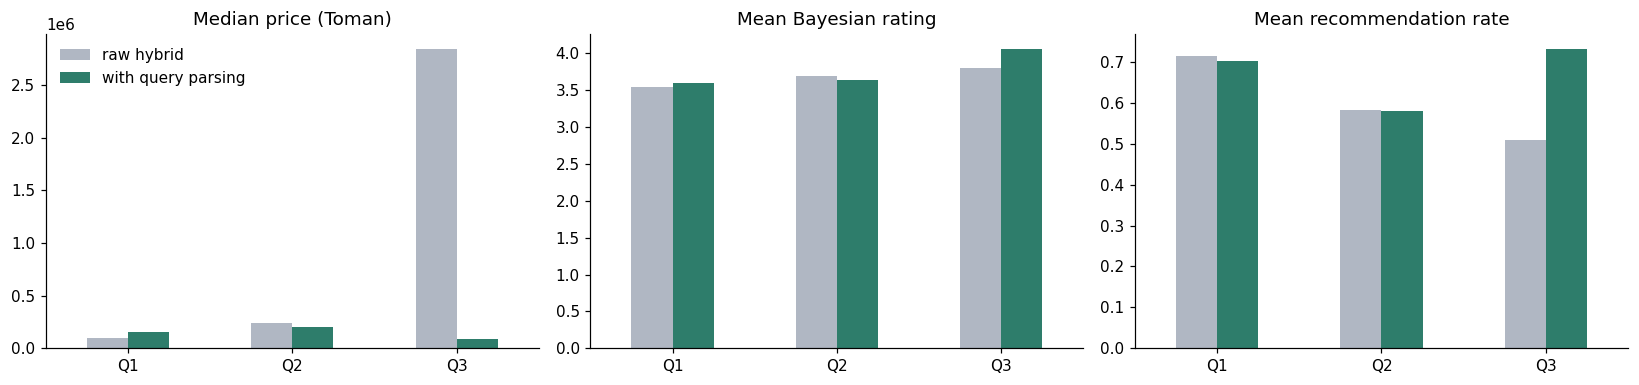

labels: 0


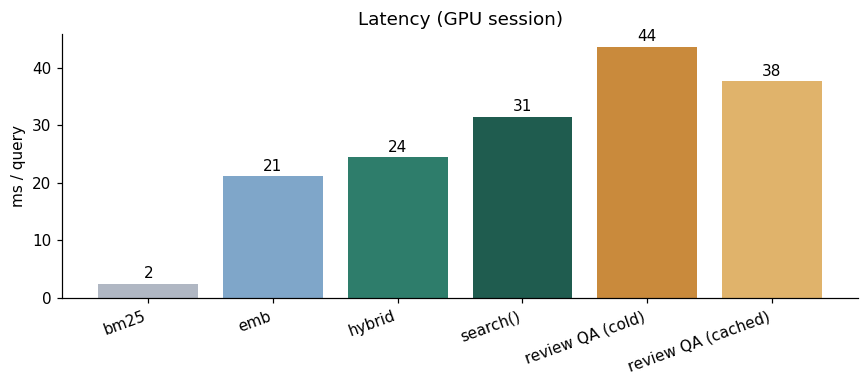

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

dev_queries = [
    "کیف دوشی روزمره", "وسیله کاربردی برای سفر", "هدفون بی‌سیم",
    "کفش ورزشی راحت برای پیاده‌روی", "هدیه‌ی ارزان برای دوست", "کتاب رمان ایرانی",
    "قاب موبایل ضدضربه", "ماسک صورت مرطوب‌کننده", "ساعت مچی مردانه کاسیو",
    "کرم ضدآفتاب پوست چرب",
]
combo = [
    "کیف روزمره ارزان که خریدارها ازش راضی باشن",
    "کفش ورزشی ارزان که خریدارها راضی باشن",
    "هدفون ارزان که خریدارها راضی باشن",
]

rows = []
for i, qq in enumerate(combo, 1):
    for name, kw in [("raw hybrid", dict(parse=False, head_boost=False)), ("with query parsing", dict())]:
        r = eng.search(qq, k=10, **kw)
        rows.append(dict(Q=f"Q{i}", setting=name, price=float(r["price_toman"].median()),
                         rating=float(r["bayes_rate"].mean()), rec=float(r["pct_rec"].mean())))
S = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col, title in zip(ax, ["price", "rating", "rec"],
                         ["Median price (Toman)", "Mean Bayesian rating", "Mean recommendation rate"]):
    S.pivot(index="Q", columns="setting", values=col)[["raw hybrid", "with query parsing"]].plot.bar(
        ax=a, rot=0, color=["#B0B7C3", "#2E7D6B"], legend=False)
    a.set_title(title)
    a.set_xlabel("")
ax[0].legend(frameon=False)
plt.tight_layout()
plt.savefig("/kaggle/working/fig_parsing_effect.png", dpi=150)
plt.show()

LABELS = {}
for p in glob.glob("/kaggle/input/**/relevance_labels*.csv", recursive=True):
    lb = pd.read_csv(p, encoding="utf-8-sig")
    lb = lb[pd.to_numeric(lb["label"], errors="coerce").isin([0, 1, 2])]
    LABELS.update({(r.query, int(r.id)): int(r.label) for r in lb.itertuples()})
print("labels:", len(LABELS))

if LABELS:
    modes = ["bm25", "emb", "hybrid"]
    M = np.full((len(modes), len(dev_queries)), np.nan)
    for mi, mode in enumerate(modes):
        for qi_, qq in enumerate(dev_queries):
            labs = [LABELS.get((qq, i)) for i in eng.ids(qq, mode, 10)]
            if None not in labs:
                M[mi, qi_] = np.mean([l >= 1 for l in labs])
    mean_p = np.nanmean(M, axis=1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2]})
    ax[0].bar(modes, mean_p, color=["#B0B7C3", "#7FA6C9", "#2E7D6B"])
    ax[0].set_ylim(0, 1)
    ax[0].set_title("Mean P@10 (human labels)")
    for x, v in enumerate(mean_p):
        ax[0].text(x, v + 0.02, f"{v:.2f}", ha="center")
    im = ax[1].imshow(np.ma.masked_invalid(M), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax[1].set_yticks(range(len(modes)))
    ax[1].set_yticklabels(modes)
    ax[1].set_xticks(range(len(dev_queries)))
    ax[1].set_xticklabels([f"D{i + 1}" for i in range(len(dev_queries))])
    ax[1].set_title("P@10 per dev query")
    plt.colorbar(im, ax=ax[1], fraction=0.03)
    plt.tight_layout()
    plt.savefig("/kaggle/working/fig_precision.png", dpi=150)
    plt.show()
    display(pd.DataFrame({"D": [f"D{i + 1}" for i in range(len(dev_queries))], "query": dev_queries}).style
            .set_properties(subset=["query"], **{"direction": "rtl", "text-align": "right"}))

eng.ids(dev_queries[0], "hybrid", 10)
lat = {}
for mode in ["bm25", "emb", "hybrid"]:
    t0 = time.time()
    for qq in dev_queries[:5]:
        eng.ids(qq, mode, 10)
    lat[mode] = (time.time() - t0) / 5 * 1000
t0 = time.time()
for qq in dev_queries[:5]:
    eng.search(qq, k=10)
lat["search()"] = (time.time() - t0) / 5 * 1000

pids = [int(x) for x in eng.search("کیف دوشی", k=6, parse=False)["id"]]
rs.cache.clear()
t0 = time.time()
for p_ in pids:
    rs.analyze(p_, "ایرادهای پرتکرار این محصول چیست؟")
lat["review QA (cold)"] = (time.time() - t0) / len(pids) * 1000
t0 = time.time()
for p_ in pids:
    rs.analyze(p_, "از چه چیزی راضی بودند؟")
lat["review QA (cached)"] = (time.time() - t0) / len(pids) * 1000

plt.figure(figsize=(8, 3.6))
plt.bar(lat.keys(), lat.values(), color=["#B0B7C3", "#7FA6C9", "#2E7D6B", "#1F5C4F", "#C98A3C", "#E0B36B"])
for x, v in enumerate(lat.values()):
    plt.text(x, v + 1, f"{v:.0f}", ha="center")
plt.xticks(rotation=20, ha="right")
plt.ylabel("ms / query")
plt.title("Latency (GPU session)")
plt.tight_layout()
plt.savefig("/kaggle/working/fig_latency.png", dpi=150)
plt.show()

In [12]:
shutil.rmtree(f"{PKG}/.bm25_cache", ignore_errors=True)
shutil.rmtree(f"{PKG}/__pycache__", ignore_errors=True)
shutil.make_archive("/kaggle/working/package", "zip", PKG)
print("package.zip", round(os.path.getsize("/kaggle/working/package.zip") / 1e6, 1), "MB")
print("comments.parquet", round(os.path.getsize("/kaggle/working/comments.parquet") / 1e6, 1), "MB")

KEEP_NAMES = {"package", "package.zip", "comments.parquet", "final_metrics.csv"}
for p in glob.glob("/kaggle/working/*"):
    name = os.path.basename(p)
    if name in KEEP_NAMES or name.startswith("fig_"):
        continue
    shutil.rmtree(p) if os.path.isdir(p) else os.remove(p)
print(sorted(os.listdir("/kaggle/working")))

package.zip 40.8 MB
comments.parquet 149.9 MB
['.virtual_documents', 'comments.parquet', 'fig_demo.html', 'fig_latency.png', 'fig_parsing_effect.png', 'package', 'package.zip']
